In [21]:
# necessary imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import logging
import sys

# plotting imports
import pandapower as pp
import pandapower.topology as top
import pandapower.plotting as plot
import simbench as sb

# simbench imports
import simbench as sb

In [22]:
# list available LV grids
lv_codes = [c for c in sb.collect_all_simbench_codes() if '1-LV' in c and '--0-sw' in c]
pd.DataFrame(lv_codes, columns=['SimBench Code'])

,SimBench Code
0,1-LV-rural1--0-sw
1,1-LV-rural2--0-sw
2,1-LV-rural3--0-sw
3,1-LV-semiurb4--0-sw
4,1-LV-semiurb5--0-sw
5,1-LV-urban6--0-sw


In [23]:
rows = []
for code in lv_codes:
    net = sb.get_simbench_net(code)
    rows.append({
        'code'    : code,
        'buses'   : len(net.bus),
        'lines'   : len(net.line),
        'loads'   : len(net.load),
        'sgen'    : len(net.sgen),    # PV / renewables
        'storage' : len(net.storage),
        'trafo_kva': net.trafo.sn_mva.sum()*1000 if len(net.trafo) else 0,
        'v_kv'    : net.bus.vn_kv.iloc[-1],
    })
pd.DataFrame(rows).set_index('code')

,buses,lines,loads,sgen,storage,trafo_kva,v_kv
code,,,,,,,
1-LV-rural1--0-sw,15,13,13,4,0,160.0,20.0
1-LV-rural2--0-sw,97,95,99,8,0,250.0,20.0
1-LV-rural3--0-sw,129,127,118,17,0,400.0,20.0
1-LV-semiurb4--0-sw,44,42,41,1,0,400.0,20.0
1-LV-semiurb5--0-sw,111,109,104,9,0,630.0,20.0
1-LV-urban6--0-sw,59,57,111,5,0,630.0,20.0


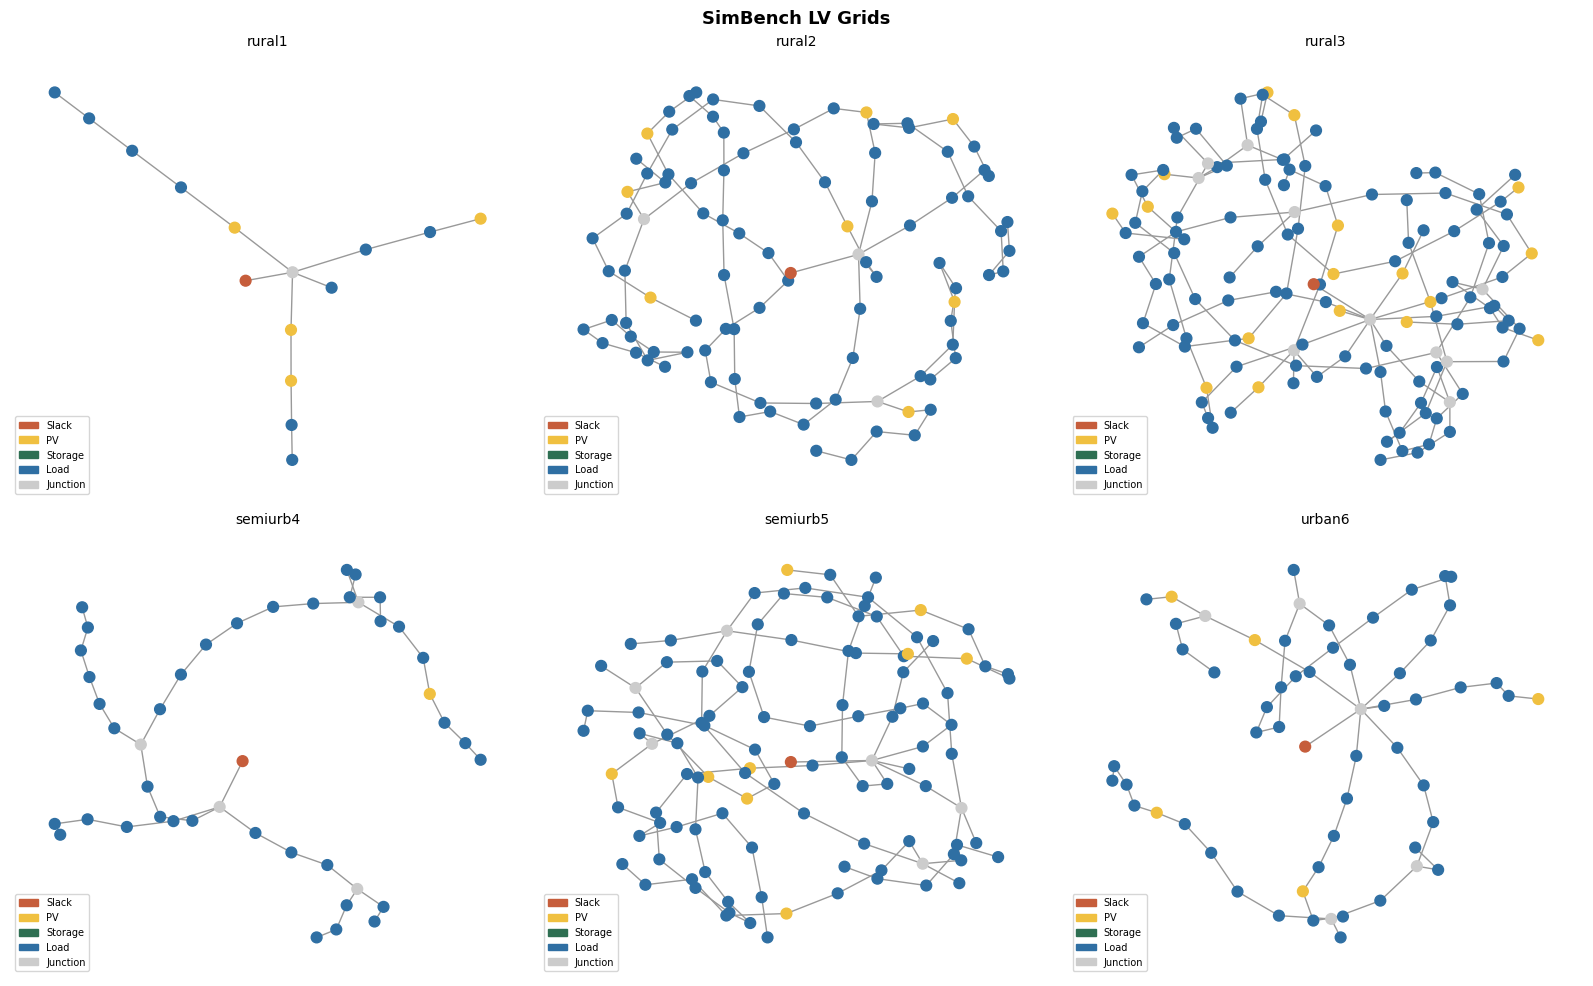

In [24]:
# network visualisation
import networkx as nx
def plot_lv_graph(code, ax=None):
    net  = sb.get_simbench_net(code)
    G    = nx.Graph()
    G.add_nodes_from(net.bus.index)
    for _, l in net.line.iterrows():
        G.add_edge(int(l.from_bus), int(l.to_bus))
    for _, t in net.trafo.iterrows():
        G.add_edge(int(t.hv_bus), int(t.lv_bus))

    root     = int(net.ext_grid.bus.iloc[0])
    init_pos = {root: (0, 0)}
    pos = nx.spring_layout(G, seed=42, pos=init_pos,
                           fixed=[root], k=0.8, iterations=200)

    load_buses  = set(net.load.bus)
    sgen_buses  = set(net.sgen.bus)
    store_buses = set(net.storage.bus) if len(net.storage) else set()
    ext_buses   = set(net.ext_grid.bus)

    colors = []
    for b in G.nodes():
        if b in ext_buses:   colors.append('#C65D3B')
        elif b in sgen_buses: colors.append('#F0C040')
        elif b in store_buses: colors.append('#2E6F52')
        elif b in load_buses: colors.append('#2F6FA3')
        else:                 colors.append('#CCCCCC')

    show = ax is None
    if show: fig, ax = plt.subplots(figsize=(7,5))
    nx.draw(G, pos, ax=ax, node_color=colors,
            node_size=60, width=1.0, edge_color='#999999', with_labels=False)

    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(color='#C65D3B', label='Slack'),
        Patch(color='#F0C040', label='PV'),
        Patch(color='#2E6F52', label='Storage'),
        Patch(color='#2F6FA3', label='Load'),
        Patch(color='#CCCCCC', label='Junction'),
    ], fontsize=7, loc='lower left')
    ax.set_title(code.replace('1-LV-','').replace('--0-sw',''), fontsize=10)
    if show: plt.show()

lv_codes = [c for c in sb.collect_all_simbench_codes()
            if '1-LV' in c and '--0-sw' in c]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, code in zip(axes.flatten(), lv_codes):
    plot_lv_graph(code, ax)
plt.suptitle('SimBench LV Grids', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()

In [25]:
# note that low voltage grids specifically maintain a typical radial structure; 
# therefore LinDistFlow should still perform if these networks were chosen

In [26]:
# exploration of available data for rural 1
lv_codes = [c for c in sb.collect_all_simbench_codes()
            if '1-LV' in c and '--0-sw' in c]

rows = []
for code in lv_codes:
    net = sb.get_simbench_net(code)
    row = {'code': code.replace('1-LV-','').replace('--0-sw','')}
    for category, df in net.profiles.items():
        # Count profiles per category
        row[category] = df.shape[1]
    rows.append(row)

pd.DataFrame(rows).set_index('code').fillna(0).astype(int)

,load,powerplants,renewables,storage
code,,,,
rural1,11,1,4,1
rural2,25,1,5,1
rural3,19,1,5,1
semiurb4,21,1,2,1
semiurb5,21,1,5,1
urban6,23,1,5,1


In [27]:
net = sb.get_simbench_net('1-LV-rural1--0-sw')
for category, df in net.profiles.items():
    print(f"\n[{category}]  {df.shape[1]} profiles, {df.shape[0]} timesteps")
    print("  ", list(df.columns[:15]), "...")


[load]  11 profiles, 35136 timesteps
   ['time', 'H0-A_qload', 'H0-A_pload', 'H0-B_qload', 'H0-B_pload', 'H0-C_qload', 'H0-C_pload', 'L1-A_qload', 'L1-A_pload', 'L2-A_qload', 'L2-A_pload'] ...

[powerplants]  1 profiles, 35136 timesteps
   ['time'] ...

[renewables]  4 profiles, 35136 timesteps
   ['time', 'PV5', 'PV6', 'PV8'] ...

[storage]  1 profiles, 0 timesteps
   ['time'] ...


In [28]:
# data exploration across grids (rural, suburban, urban)
lv_codes = [c for c in sb.collect_all_simbench_codes()
            if '1-LV' in c and '--0-sw' in c]

for code in lv_codes:
    net = sb.get_simbench_net(code)
    short = code.replace('1-LV-','').replace('--0-sw','')
    print(f"\n{'='*60}")
    print(f" {short}")
    print(f"{'='*60}")
    for category, df in net.profiles.items():
        cols = [c for c in df.columns if c != 'time']
        if cols:
            print(f"  [{category}] {len(cols)} profiles:")
            print(f"    {cols}")


 rural1
  [load] 10 profiles:
    ['H0-A_qload', 'H0-A_pload', 'H0-B_qload', 'H0-B_pload', 'H0-C_qload', 'H0-C_pload', 'L1-A_qload', 'L1-A_pload', 'L2-A_qload', 'L2-A_pload']
  [renewables] 3 profiles:
    ['PV5', 'PV6', 'PV8']

 rural2
  [load] 24 profiles:
    ['G1-B_qload', 'G1-B_pload', 'G1-C_qload', 'G1-C_pload', 'G2-A_qload', 'G2-A_pload', 'G3-A_qload', 'G3-A_pload', 'G4-A_qload', 'G4-A_pload', 'G5-A_qload', 'G5-A_pload', 'G6-A_qload', 'G6-A_pload', 'H0-A_qload', 'H0-A_pload', 'H0-B_qload', 'H0-B_pload', 'H0-C_qload', 'H0-C_pload', 'H0-G_qload', 'H0-G_pload', 'H0-L_qload', 'H0-L_pload']
  [renewables] 4 profiles:
    ['PV1', 'PV3', 'PV4', 'PV7']

 rural3
  [load] 18 profiles:
    ['G1-C_qload', 'G1-C_pload', 'G4-A_qload', 'G4-A_pload', 'G5-A_qload', 'G5-A_pload', 'G6-A_qload', 'G6-A_pload', 'H0-A_qload', 'H0-A_pload', 'H0-B_qload', 'H0-B_pload', 'H0-C_qload', 'H0-C_pload', 'H0-G_qload', 'H0-G_pload', 'H0-L_qload', 'H0-L_pload']
  [renewables] 4 profiles:
    ['PV1', 'PV3', 'PV4'

In [29]:
# HP and EV data contained in dataset, but not assigned to grids; find HP/EV data to assign to prosumers
# check 1: check indices 
net_c = sb.get_simbench_net('1-complete_data-mixed-all-0-sw')

for cat, df in net_c.profiles.items():
    cols = [c for c in df.columns if c != 'time']
    if cols:
        print(f"\n[{cat}]  {len(cols)} profiles")
        print(cols)


[load]  142 profiles
['BL-H_qload', 'BL-H_pload', 'G0-A_qload', 'G0-A_pload', 'G0-M_qload', 'G0-M_pload', 'G1-A_qload', 'G1-A_pload', 'G1-B_qload', 'G1-B_pload', 'G1-C_qload', 'G1-C_pload', 'G2-A_qload', 'G2-A_pload', 'G3-A_qload', 'G3-A_pload', 'G3-H_qload', 'G3-H_pload', 'G3-M_qload', 'G3-M_pload', 'G4-A_qload', 'G4-A_pload', 'G4-B_qload', 'G4-B_pload', 'G4-M_qload', 'G4-M_pload', 'G5-A_qload', 'G5-A_pload', 'G6-A_qload', 'G6-A_pload', 'H0-A_qload', 'H0-A_pload', 'H0-B_qload', 'H0-B_pload', 'H0-C_qload', 'H0-C_pload', 'H0-G_qload', 'H0-G_pload', 'H0-L_qload', 'H0-L_pload', 'L0-A_qload', 'L0-A_pload', 'L1-A_qload', 'L1-A_pload', 'L2-A_qload', 'L2-A_pload', 'L2-M_qload', 'L2-M_pload', 'WB-H_qload', 'WB-H_pload', 'lv_rural1_qload', 'lv_rural1_pload', 'lv_rural2_qload', 'lv_rural2_pload', 'lv_rural3_qload', 'lv_rural3_pload', 'lv_semiurb4_pload', 'lv_semiurb4_qload', 'lv_semiurb5_pload', 'lv_semiurb5_qload', 'lv_urban6_pload', 'lv_urban6_qload', 'mv_rural_pload', 'mv_rural_qload', 'mv_s

In [ ]:
# location not obvious from indices; paper and GitHub review 

In [ ]:
# location information (from descriptive SimBench Paper):
# Heat pumps: HP-H1, HP-H2, HP-H3, HP-H4 (Hanover) and HP-L1, HP-L2, HP-L3, HP-L4 (Lübeck), air and soil source, different operating modes
# EVs: HL-1-11, HL-2-11, HL-1-3.7, HL-2-3.7, HL-3-3.7 (household charging) and OL-1-50, OL-1-22, OL-1-11, OL-1-3.7, OL-2-3.7 (workplace charging), at 3.7/11/22/50 kW
# Storage: 48 profiles exist (40 self-consumption + 8 grid-supporting)

In [30]:
# goal: identify missing HP, EV profile
# Method 1 — get overview of all profiles
all_profiles = sb.get_all_simbench_profiles(0)  # scenario 0
for cat, df in all_profiles.items():
    cols = [c for c in df.columns if c != 'time']
    hp = [c for c in cols if 'HP' in c or 'WP' in c]
    ev = [c for c in cols if 'HL' in c or 'OL' in c or 'BEV' in c]
    bat = [c for c in cols if 'BAT' in c]
    if hp or ev or bat:
        print(f"\n[{cat}]")
        if hp:  print(f"  HP:      {hp}")
        if ev:  print(f"  EV:      {ev}")
        if bat: print(f"  Storage: {bat}")



[load]
  EV:      ['HLS_A_3.7_pload', 'HLS_A_3.7_qload', 'HLS_B_3.7_pload', 'HLS_B_3.7_qload', 'HLS_C_3.7_pload', 'HLS_C_3.7_qload', 'HLS_A_11.0_pload', 'HLS_A_11.0_qload', 'HLS_B_11.0_pload', 'HLS_B_11.0_qload', 'HLS_A_22.0_pload', 'HLS_A_22.0_qload']

[renewables]
  HP:      ['WP1', 'WP2', 'WP3', 'WP4', 'WP5', 'WP6', 'WP7', 'WP8', 'WP9', 'WP10', 'WP11', 'WP12']


In [31]:
# Method 2 — check storage profiles specifically
# Paper says 48 storage profiles exist; we kept seeing 0 timesteps
all_profiles = sb.get_all_simbench_profiles(0)
if 'storage' in all_profiles:
    s = all_profiles['storage']
    print(f"Storage profiles: {s.shape}")
    print(list(s.columns[:20]))

Storage profiles: (0, 3)
['time', 'PV_Battery', 'E_Mobility']


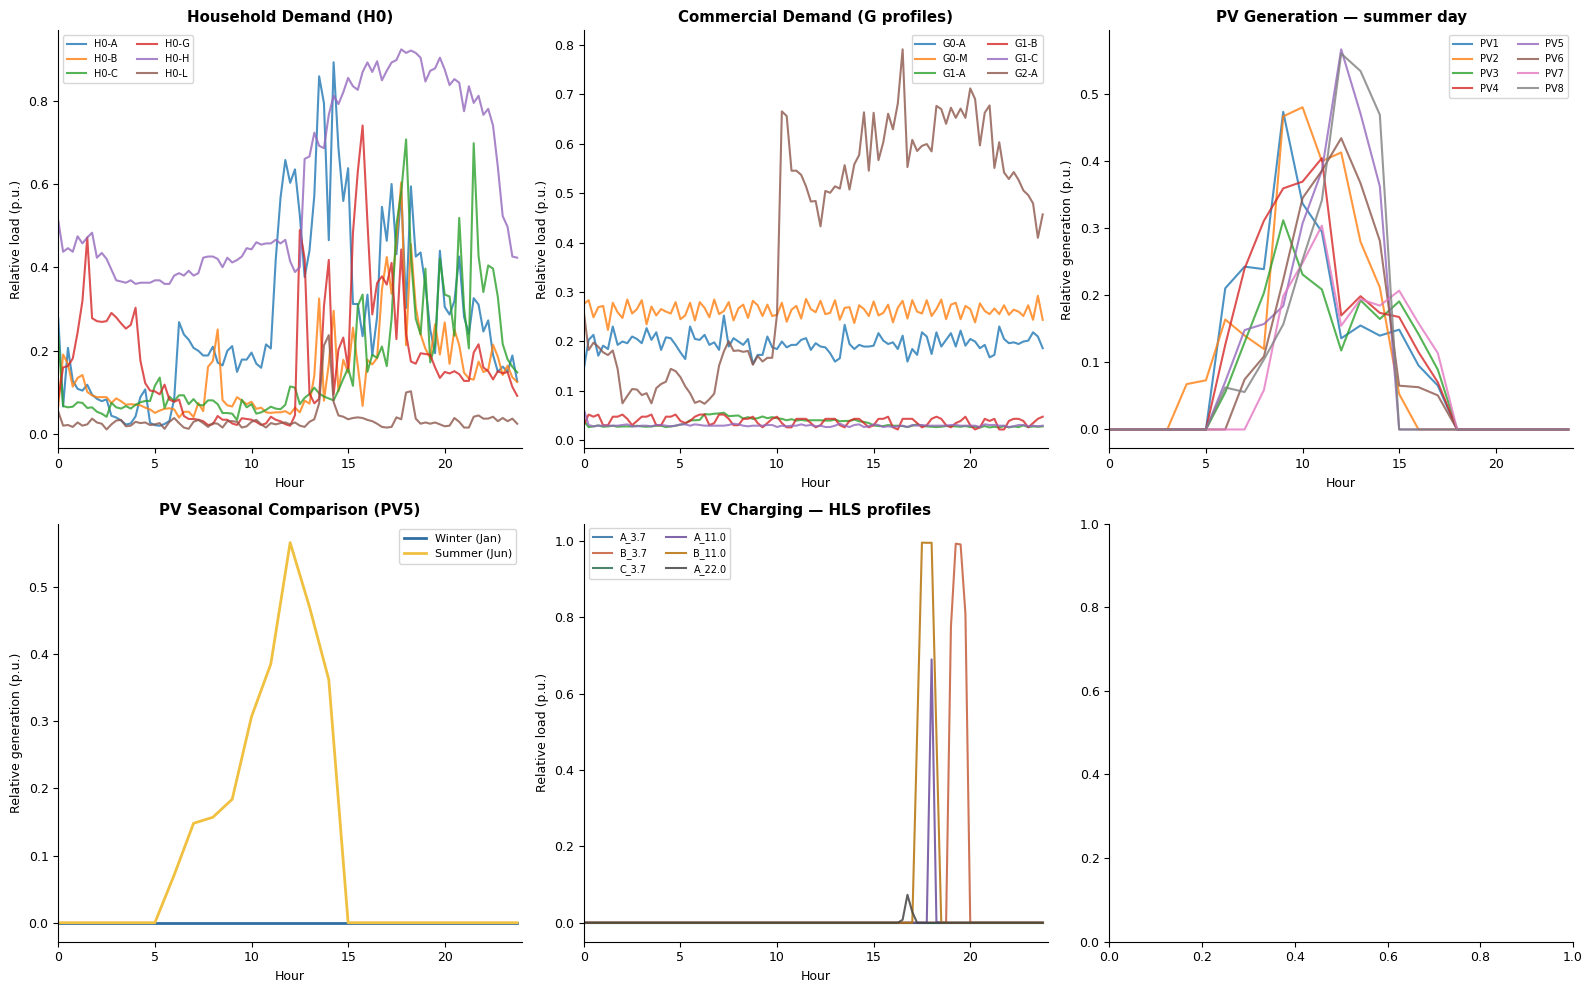

In [39]:
# Output Checks 
# Load all profiles
all_profiles = sb.get_all_simbench_profiles(0)
load_p = all_profiles['load']
renew  = all_profiles['renewables']

# First day (96 × 15min = 24h), convert index to hours
t = np.arange(96) * 0.25

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})

# ── 1. Household demand (H0 variants) ─────────────────────────────────────────
ax = axes[0, 0]
h0_cols = [c for c in load_p.columns if c.startswith('H0') and 'pload' in c]
for col in h0_cols:
    ax.plot(t, load_p[col].iloc[:96].values, label=col.replace('_pload',''), alpha=0.8)
ax.set_title('Household Demand (H0)', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)

# ── 2. Commercial demand (G profiles) ─────────────────────────────────────────
ax = axes[0, 1]
g_cols = [c for c in load_p.columns if c.startswith('G') and 'pload' in c][:6]
for col in g_cols:
    ax.plot(t, load_p[col].iloc[:96].values, label=col.replace('_pload',''), alpha=0.8)
ax.set_title('Commercial Demand (G profiles)', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)

# ── 3. PV generation ──────────────────────────────────────────────────────────
ax = axes[0, 2]
# Use a summer day (~day 180 = step 180*96)
summer_start = 180 * 96
pv_cols = [c for c in renew.columns if c.startswith('PV')]
for col in pv_cols:
    ax.plot(t, renew[col].iloc[summer_start:summer_start+96].values,
            label=col, alpha=0.8)
ax.set_title('PV Generation — summer day', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative generation (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)

# ── 4. PV — winter vs summer comparison (one profile) ─────────────────────────
ax = axes[1, 0]
winter_start = 10 * 96   # Jan day 10
col = 'PV5'
ax.plot(t, renew[col].iloc[winter_start:winter_start+96].values,
        color='#2F6FA3', label='Winter (Jan)', linewidth=2)
ax.plot(t, renew[col].iloc[summer_start:summer_start+96].values,
        color='#F0C040', label='Summer (Jun)', linewidth=2)
ax.set_title(f'PV Seasonal Comparison ({col})', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative generation (p.u.)')
ax.legend(fontsize=8); ax.set_xlim(0, 24)

# ── 5. EV charging profiles (HLS) ─────────────────────────────────────────────
ax = axes[1, 1]
ev_cols = [c for c in load_p.columns if 'HLS' in c and 'pload' in c]
colors = ['#2F6FA3','#C65D3B','#2E6F52','#6B4C9A','#B5720A','#444444']
for col, color in zip(ev_cols, colors):
    label = col.replace('_pload','').replace('HLS_','')
    ax.plot(t, load_p[col].iloc[:96].values, label=label, color=color, alpha=0.85)
ax.set_title('EV Charging — HLS profiles', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)

plt.tight_layout()
plt.show()

In [ ]:
# find missing HP and BESS

# Find where SimBench stores its CSV data files on your machine
sb_path = os.path.dirname(sb.__file__)
print("SimBench installed at:", sb_path)

# Walk through and find all CSV files
for root, dirs, files in os.walk(sb_path):
    for f in files:
        if f.endswith('.csv'):
            print(os.path.join(root, f))

SimBench installed at: /opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_output_folder/Line.csv
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_output_folder/LoadProfile.csv
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_output_folder/RES.csv
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_output_folder/ExternalNet.csv
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_output_folder/TransformerType.csv
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_output_folder/Shunt.csv
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_output_folder/StudyCases.csv
/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/test/converter/test_network_out

In [33]:
# Read the LoadProfile CSV directly
path = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/LoadProfile.csv'
lp = pd.read_csv(path, sep=';', index_col=0)

print("Shape:", lp.shape)
print("\nAll columns:")
print(list(lp.columns))

Shape: (35136, 192)

All columns:
['BL-H_qload', 'BL-H_pload', 'G0-A_qload', 'G0-A_pload', 'G0-M_qload', 'G0-M_pload', 'G1-A_qload', 'G1-A_pload', 'G1-B_qload', 'G1-B_pload', 'G1-C_qload', 'G1-C_pload', 'G2-A_qload', 'G2-A_pload', 'G3-A_qload', 'G3-A_pload', 'G3-H_qload', 'G3-H_pload', 'G3-M_qload', 'G3-M_pload', 'G4-A_qload', 'G4-A_pload', 'G4-B_qload', 'G4-B_pload', 'G4-H_qload', 'G4-H_pload', 'G4-M_qload', 'G4-M_pload', 'G5-A_qload', 'G5-A_pload', 'G6-A_qload', 'G6-A_pload', 'H0-A_qload', 'H0-A_pload', 'H0-B_qload', 'H0-B_pload', 'H0-C_qload', 'H0-C_pload', 'H0-G_qload', 'H0-G_pload', 'H0-H_qload', 'H0-H_pload', 'H0-L_qload', 'H0-L_pload', 'L0-A_qload', 'L0-A_pload', 'L1-A_qload', 'L1-A_pload', 'L2-A_qload', 'L2-A_pload', 'L2-M_qload', 'L2-M_pload', 'WB-H_qload', 'WB-H_pload', 'lv_rural1_qload', 'lv_rural1_pload', 'lv_rural2_qload', 'lv_rural2_pload', 'lv_rural3_qload', 'lv_rural3_pload', 'lv_semiurb4_pload', 'lv_semiurb4_qload', 'lv_semiurb5_pload', 'lv_semiurb5_qload', 'lv_urban6_

In [ ]:
# check StorageProfile (scenarios 1 and 2 have it, 0 doesn't)
path_s1 = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-1-sw/StorageProfile.csv'
sp = pd.read_csv(path_s1, sep=';', index_col=0)
print("Storage profiles shape:", sp.shape)
print("Columns:", list(sp.columns))

Storage profiles shape: (35136, 60)
Columns: ['Storage_PV8_L1-A', 'Storage_PV5_L2-A', 'Storage_PV5_L1-A', 'Storage_PV8_L2-A', 'Storage_PV3_H0-A', 'Storage_PV7_H0-G', 'Storage_PV4_H0-A', 'Storage_PV3_G1-B', 'Storage_PV7_H0-C', 'Storage_PV1_H0-B', 'Storage_PV3_G6-A', 'Storage_PV3_H0-G', 'Storage_PV4_H0-G', 'Storage_PV3_H0-B', 'Storage_PV4_H0-L', 'Storage_PV1_H0-C', 'Storage_PV7_H0-B', 'Storage_PV7_H0-L', 'Storage_PV4_H0-C', 'Storage_PV5_H0-A', 'Storage_PV5_G2-A', 'Storage_PV5_H0-G', 'Storage_PV5_G4-A', 'Storage_PV6_H0-C', 'Storage_PV5_H0-L', 'Storage_PV5_G4-B', 'Storage_PV8_H0-B', 'Storage_PV2_H0-G', 'Storage_PV2_H0-B', 'Storage_PV5_H0-B', 'Storage_PV8_G5-A', 'Storage_PV5_G1-C', 'Storage_PV2_H0-A', 'Storage_PV2_G3-A', 'Storage_PV8_H0-L', 'Storage_PV6_H0-B', 'Storage_PV8_H0-C', 'Storage_PV4_G4-M', 'Storage_PV1_G3-M', 'Storage_PV4_G2-A', 'Storage_PV4_3%_e_MWh', 'Storage_PV6_3%_e_MWh', 'Storage_WP10_3%_e_MWh', 'Storage_WP4_3%_e_MWh', 'Storage_WP7_3%_e_MWh', 'Storage_WP11_3%_e_MWh', 'Storage

In [ ]:
# Load.csv to understand what elements reference which profiles
path_l = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/Load.csv'
loads = pd.read_csv(path_l, sep=';')
print("Load element columns:", list(loads.columns))
print("\nUnique profile names used:")
print(sorted(loads['profile'].dropna().unique()) if 'profile' in loads.columns else loads.head())

Load element columns: ['id', 'node', 'profile', 'pLoad', 'qLoad', 'sR', 'subnet', 'voltLvl']

Unique profile names used:
['BL-H', 'G0-A', 'G0-M', 'G1-A', 'G1-B', 'G1-C', 'G2-A', 'G3-A', 'G3-H', 'G3-M', 'G4-A', 'G4-B', 'G4-M', 'G5-A', 'G6-A', 'H0-A', 'H0-B', 'H0-C', 'H0-G', 'H0-L', 'HS0', 'HS1', 'HS10', 'HS11', 'HS12', 'HS13', 'HS14', 'HS15', 'HS16', 'HS17', 'HS18', 'HS19', 'HS2', 'HS20', 'HS21', 'HS22', 'HS23', 'HS24', 'HS25', 'HS26', 'HS27', 'HS3', 'HS4', 'HS5', 'HS6', 'HS7', 'HS8', 'HS9', 'HSexp0', 'HSexp1', 'L0-A', 'L1-A', 'L2-A', 'L2-M', 'WB-H', 'hv_mixed1', 'hv_mixed2', 'hv_mixed3', 'hv_urban', 'lv_rural1', 'lv_rural2', 'lv_rural3', 'lv_semiurb4', 'lv_semiurb5', 'lv_urban6', 'mv_add1', 'mv_add2', 'mv_comm', 'mv_rural', 'mv_semiurb', 'mv_urban']


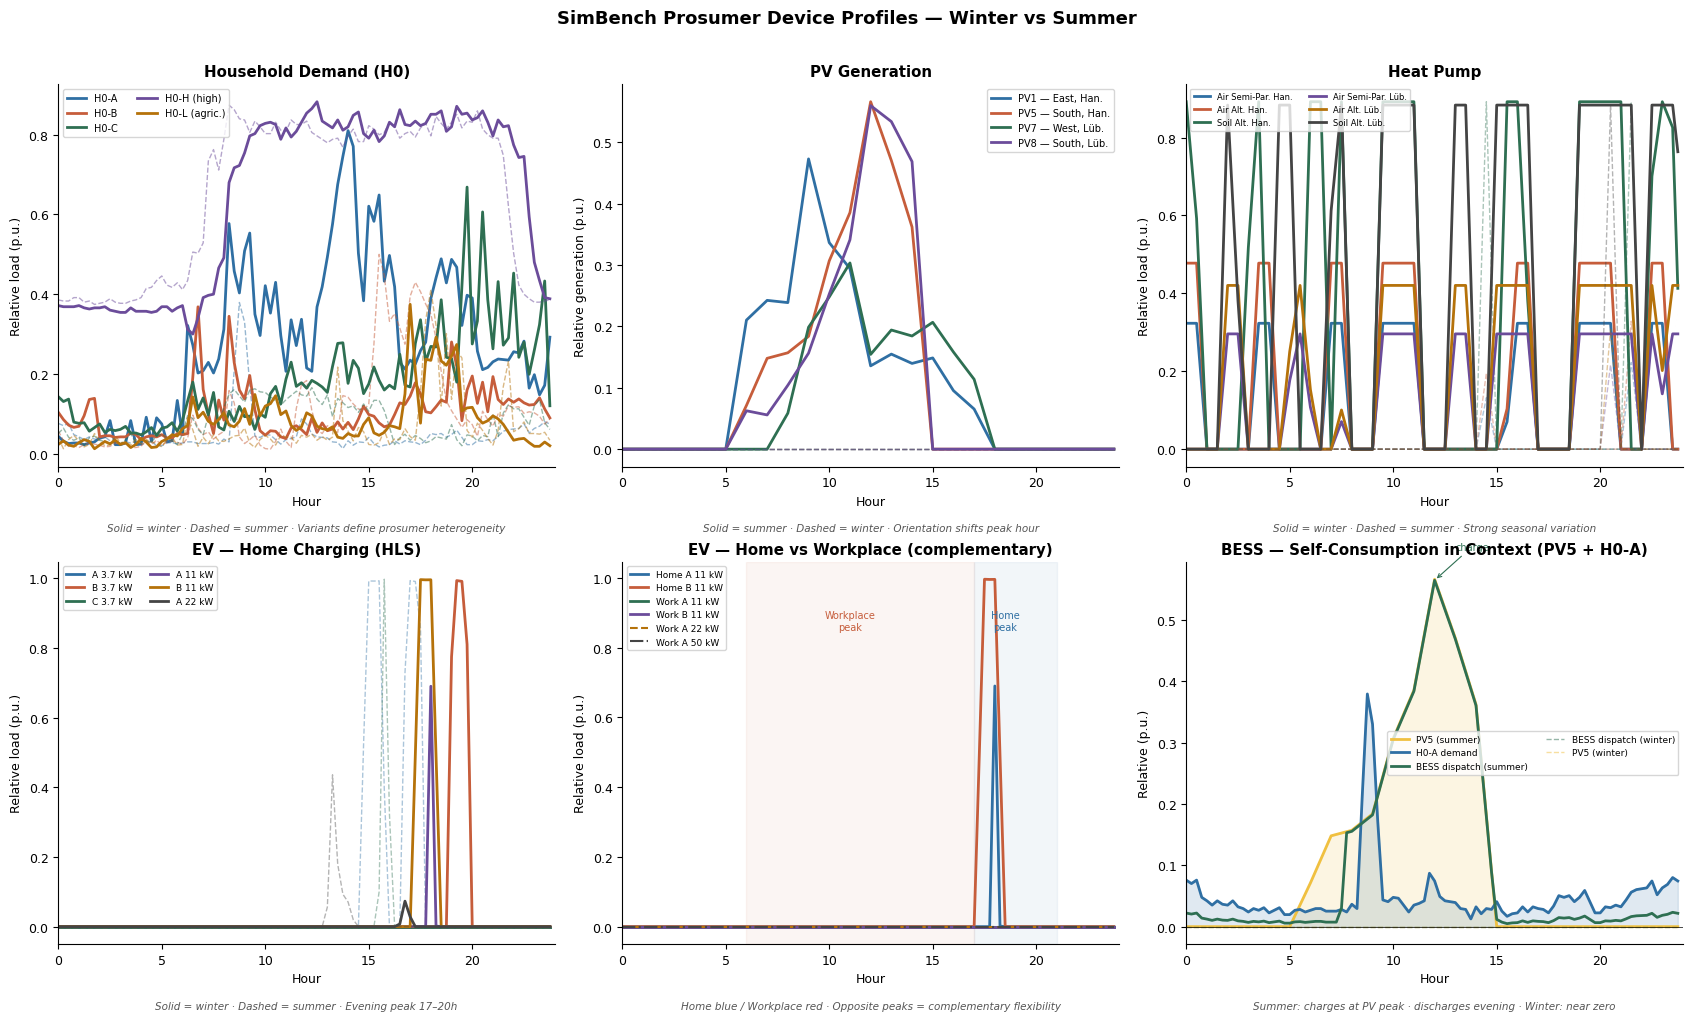

In [37]:
# Load CSVs
path_lp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/LoadProfile.csv'
path_rp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/RESProfile.csv'
path_sp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-1-sw/StorageProfile.csv'
lp = pd.read_csv(path_lp, sep=';', index_col=0)
rp = pd.read_csv(path_rp, sep=';', index_col=0)
sp = pd.read_csv(path_sp, sep=';', index_col=0)

t      = np.arange(96) * 0.25
winter = slice(10*96,  10*96+96)
summer = slice(180*96, 180*96+96)

C = ['#2F6FA3','#C65D3B','#2E6F52','#6B4C9A','#B5720A','#444444','#888888','#AA3377']

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
plt.rcParams.update({'font.size':9,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42})

def note(ax, txt):
    ax.text(0.5, -0.17, txt, transform=ax.transAxes, ha='center',
            fontsize=7.5, color='#555555', style='italic')

# ── 1. Household demand ───────────────────────────────────────────────────────
ax = axes[0, 0]
h0 = [('H0-A', 'H0-A_pload', C[0]),
      ('H0-B', 'H0-B_pload', C[1]),
      ('H0-C', 'H0-C_pload', C[2]),
      ('H0-H (high)', 'H0-H_pload', C[3]),
      ('H0-L (agric.)', 'H0-L_pload', C[4])]
for label, col, color in h0:
    ax.plot(t, lp[col].iloc[winter].values, color=color, lw=2.0, label=label)
    ax.plot(t, lp[col].iloc[summer].values, color=color, lw=1.0, ls='--', alpha=0.5)
ax.set_title('Household Demand (H0)', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2)
ax.set_xlim(0, 24)
note(ax, 'Solid = winter · Dashed = summer · Variants define prosumer heterogeneity')

# ── 2. PV generation ──────────────────────────────────────────────────────────
ax = axes[0, 1]
pv = [('PV1 — East, Han.',  'PV1', C[0]),
      ('PV5 — South, Han.', 'PV5', C[1]),
      ('PV7 — West, Lüb.',  'PV7', C[2]),
      ('PV8 — South, Lüb.', 'PV8', C[3])]
for label, col, color in pv:
    ax.plot(t, rp[col].iloc[summer].values, color=color, lw=2.0, label=label)
    ax.plot(t, rp[col].iloc[winter].values, color=color, lw=1.0, ls='--', alpha=0.5)
ax.set_title('PV Generation', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative generation (p.u.)')
ax.legend(fontsize=7)
ax.set_xlim(0, 24)
note(ax, 'Solid = summer · Dashed = winter · Orientation shifts peak hour')

# ── 3. Heat pump ──────────────────────────────────────────────────────────────
ax = axes[0, 2]
hp = [('Air Semi-Par. Han.', 'Air_Semi-Parallel_1_pload', C[0]),
      ('Air Alt. Han.',       'Air_Alternative_1_pload',   C[1]),
      ('Soil Alt. Han.',      'Soil_Alternative_1_pload',  C[2]),
      ('Air Semi-Par. Lüb.', 'Air_Semi-Parallel_2_pload', C[3]),
      ('Air Alt. Lüb.',       'Air_Alternative_2_pload',   C[4]),
      ('Soil Alt. Lüb.',      'Soil_Alternative_2_pload',  C[5])]
for label, col, color in hp:
    ax.plot(t, lp[col].iloc[winter].values, color=color, lw=2.0, label=label)
    ax.plot(t, lp[col].iloc[summer].values, color=color, lw=1.0, ls='--', alpha=0.4)
ax.set_title('Heat Pump', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=6, ncol=2)
ax.set_xlim(0, 24)
note(ax, 'Solid = winter · Dashed = summer · Strong seasonal variation')

# ── 4. EV home charging (HLS) ─────────────────────────────────────────────────
ax = axes[1, 0]
hls = [('A 3.7 kW',  'HLS_A_3.7_pload',  C[0]),
       ('B 3.7 kW',  'HLS_B_3.7_pload',  C[1]),
       ('C 3.7 kW',  'HLS_C_3.7_pload',  C[2]),
       ('A 11 kW',   'HLS_A_11.0_pload', C[3]),
       ('B 11 kW',   'HLS_B_11.0_pload', C[4]),
       ('A 22 kW',   'HLS_A_22.0_pload', C[5])]
for label, col, color in hls:
    ax.plot(t, lp[col].iloc[:96].values,   color=color, lw=2.0, label=label)
    ax.plot(t, lp[col].iloc[summer].values, color=color, lw=1.0, ls='--', alpha=0.4)
ax.set_title('EV — Home Charging (HLS)', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=6.5, ncol=2)
ax.set_xlim(0, 24)
note(ax, 'Solid = winter · Dashed = summer · Evening peak 17–20h')

# ── 5. EV workplace (APLS) vs home ────────────────────────────────────────────
ax = axes[1, 1]
ev_comp = [('Home A 11 kW',  'HLS_A_11.0_pload',  C[0], '-',  2.0),
           ('Home B 11 kW',  'HLS_B_11.0_pload',  C[1], '-',  2.0),
           ('Work A 11 kW',  'APLS_A_11.0_pload', C[2], '-',  2.0),
           ('Work B 11 kW',  'APLS_B_11.0_pload', C[3], '-',  2.0),
           ('Work A 22 kW',  'APLS_A_22.0_pload', C[4], '--', 1.5),
           ('Work A 50 kW',  'APLS_A_50.0_pload', C[5], '-.', 1.5)]
for label, col, color, ls, lw in ev_comp:
    ax.plot(t, lp[col].iloc[:96].values, color=color, lw=lw, ls=ls, label=label)
ax.axvspan(6, 17, alpha=0.06, color='#C65D3B', label='_workplace window')
ax.axvspan(17, 21, alpha=0.06, color='#2F6FA3', label='_home window')
ax.annotate('Workplace\npeak', xy=(11, 0.85), fontsize=7, color='#C65D3B',
            ha='center')
ax.annotate('Home\npeak', xy=(18.5, 0.85), fontsize=7, color='#2F6FA3',
            ha='center')
ax.set_title('EV — Home vs Workplace (complementary)', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=6.5)
ax.set_xlim(0, 24)
note(ax, 'Home blue / Workplace red · Opposite peaks = complementary flexibility')

# ── 6. BESS in context (PV + demand + dispatch) ───────────────────────────────
ax = axes[1, 2]
pv_s   = rp['PV5'].iloc[summer].values
load_s = lp['H0-A_pload'].iloc[summer].values
bess_s = sp['Storage_PV5_H0-A'].iloc[summer].values
pv_w   = rp['PV5'].iloc[winter].values
bess_w = sp['Storage_PV5_H0-A'].iloc[winter].values

ax.fill_between(t, 0, pv_s,   alpha=0.15, color='#F0C040')
ax.fill_between(t, 0, load_s, alpha=0.15, color='#2F6FA3')
ax.plot(t, pv_s,   color='#F0C040', lw=2.0, label='PV5 (summer)')
ax.plot(t, load_s, color='#2F6FA3', lw=2.0, label='H0-A demand')
ax.plot(t, bess_s, color='#2E6F52', lw=2.0, label='BESS dispatch (summer)')
ax.plot(t, bess_w, color='#2E6F52', lw=1.0, ls='--', alpha=0.5,
        label='BESS dispatch (winter)')
ax.plot(t, pv_w,   color='#F0C040', lw=1.0, ls='--', alpha=0.5,
        label='PV5 (winter)')
ax.axhline(0, color='k', lw=0.5)

# charge/discharge annotation
pos_mask = bess_s > 0.01
neg_mask = bess_s < -0.01
if pos_mask.any():
    peak_t = t[pos_mask][np.argmax(bess_s[pos_mask])]
    ax.annotate('charge', xy=(peak_t, bess_s[pos_mask].max()),
                xytext=(peak_t+1, bess_s[pos_mask].max()+0.05),
                fontsize=7, color='#2E6F52',
                arrowprops=dict(arrowstyle='->', color='#2E6F52', lw=0.8))
if neg_mask.any():
    trough_t = t[neg_mask][np.argmin(bess_s[neg_mask])]
    ax.annotate('discharge', xy=(trough_t, bess_s[neg_mask].min()),
                xytext=(trough_t+1, bess_s[neg_mask].min()-0.08),
                fontsize=7, color='#2E6F52',
                arrowprops=dict(arrowstyle='->', color='#2E6F52', lw=0.8))

ax.set_title('BESS — Self-Consumption in Context (PV5 + H0-A)',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative (p.u.)')
ax.legend(fontsize=6.5, ncol=2)
ax.set_xlim(0, 24)
note(ax, 'Summer: charges at PV peak · discharges evening · Winter: near zero')

fig.suptitle('SimBench Prosumer Device Profiles — Winter vs Summer',
             fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

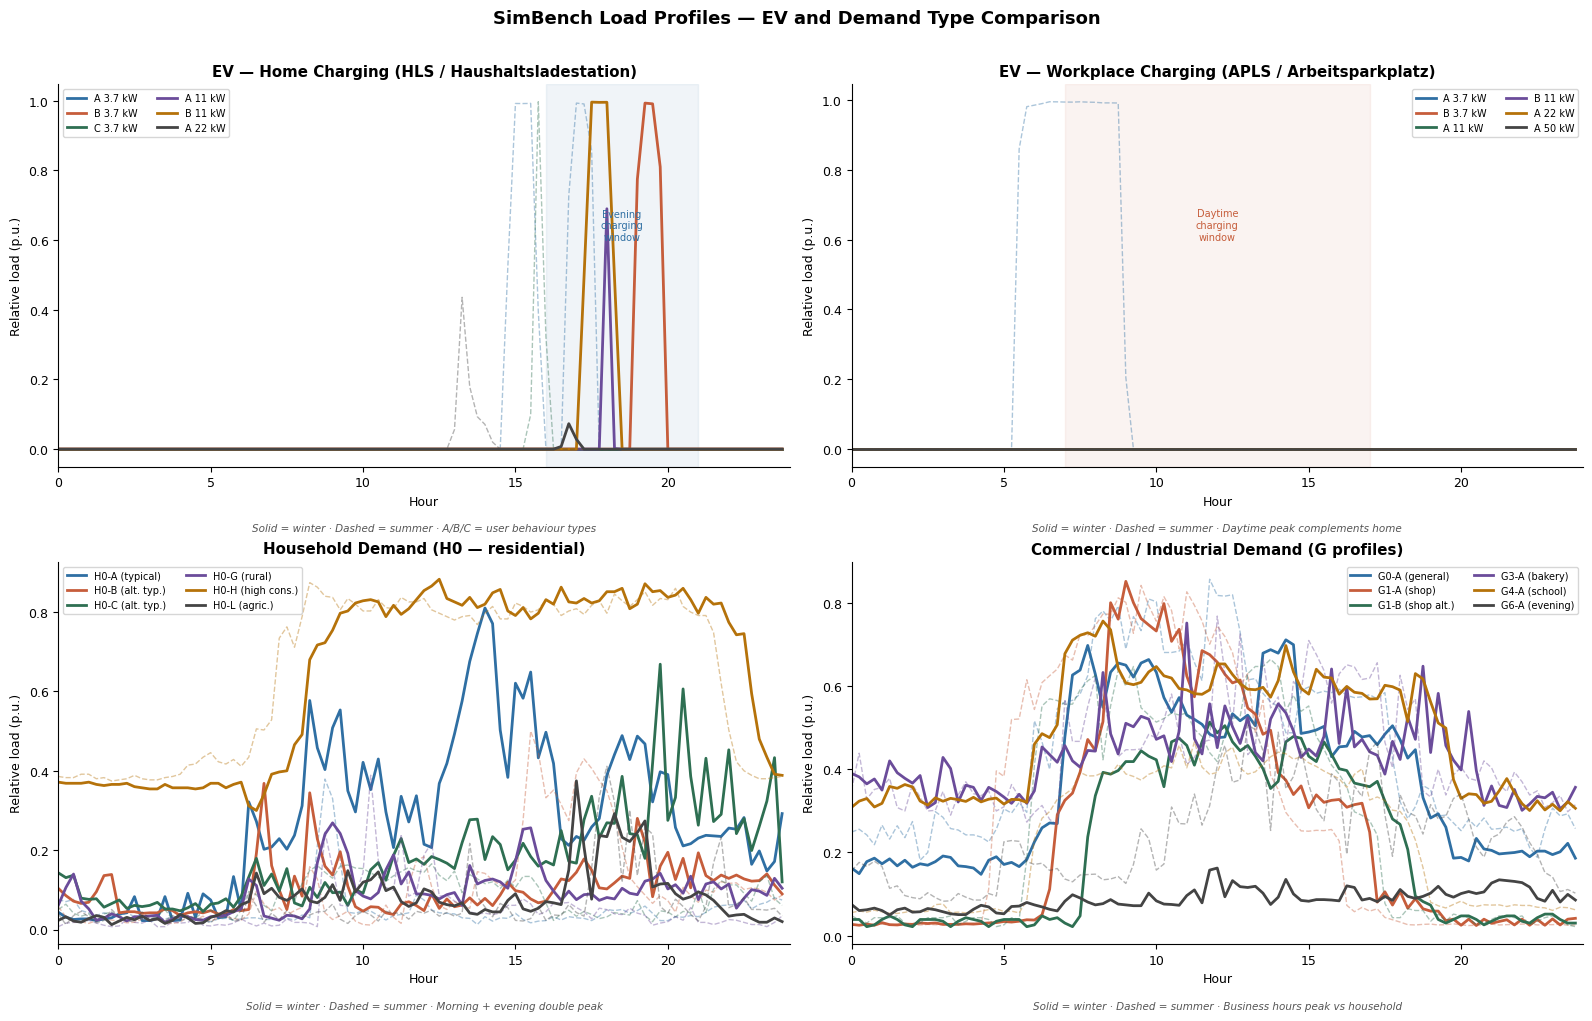

In [40]:
# split EV plots work and home 
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plt.rcParams.update({'font.size':9,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42})
C = ['#2F6FA3','#C65D3B','#2E6F52','#6B4C9A','#B5720A','#444444','#888888']

def note(ax, txt):
    ax.text(0.5, -0.17, txt, transform=ax.transAxes, ha='center',
            fontsize=7.5, color='#555555', style='italic')

# ── 1. EV home charging (HLS) ─────────────────────────────────────────────────
ax = axes[0, 0]
hls = [('A 3.7 kW',  'HLS_A_3.7_pload',  C[0]),
       ('B 3.7 kW',  'HLS_B_3.7_pload',  C[1]),
       ('C 3.7 kW',  'HLS_C_3.7_pload',  C[2]),
       ('A 11 kW',   'HLS_A_11.0_pload', C[3]),
       ('B 11 kW',   'HLS_B_11.0_pload', C[4]),
       ('A 22 kW',   'HLS_A_22.0_pload', C[5])]
for label, col, color in hls:
    ax.plot(t, lp[col].iloc[:96].values,    color=color, lw=2.0,
            label=label)
    ax.plot(t, lp[col].iloc[summer].values, color=color, lw=1.0,
            ls='--', alpha=0.4)
ax.axvspan(16, 21, alpha=0.07, color='#2F6FA3')
ax.annotate('Evening\ncharging\nwindow', xy=(18.5, 0.6), fontsize=7,
            color='#2F6FA3', ha='center')
ax.set_title('EV — Home Charging (HLS / Haushaltsladestation)',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)
note(ax, 'Solid = winter · Dashed = summer · A/B/C = user behaviour types')

# ── 2. EV workplace charging (APLS) ───────────────────────────────────────────
ax = axes[0, 1]
apls = [('A 3.7 kW',  'APLS_A_3.7_pload',  C[0]),
        ('B 3.7 kW',  'APLS_B_3.7_pload',  C[1]),
        ('A 11 kW',   'APLS_A_11.0_pload', C[2]),
        ('B 11 kW',   'APLS_B_11.0_pload', C[3]),
        ('A 22 kW',   'APLS_A_22.0_pload', C[4]),
        ('A 50 kW',   'APLS_A_50.0_pload', C[5])]
for label, col, color in apls:
    ax.plot(t, lp[col].iloc[:96].values,    color=color, lw=2.0,
            label=label)
    ax.plot(t, lp[col].iloc[summer].values, color=color, lw=1.0,
            ls='--', alpha=0.4)
ax.axvspan(7, 17, alpha=0.07, color='#C65D3B')
ax.annotate('Daytime\ncharging\nwindow', xy=(12, 0.6), fontsize=7,
            color='#C65D3B', ha='center')
ax.set_title('EV — Workplace Charging (APLS / Arbeitsparkplatz)',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)
note(ax, 'Solid = winter · Dashed = summer · Daytime peak complements home')


# household demand vs. industry demand 
# ── 3. Household demand (H0) ──────────────────────────────────────────────────
ax = axes[1, 0]
h0 = [('H0-A (typical)',    'H0-A_pload', C[0]),
      ('H0-B (alt. typ.)',  'H0-B_pload', C[1]),
      ('H0-C (alt. typ.)',  'H0-C_pload', C[2]),
      ('H0-G (rural)',      'H0-G_pload', C[3]),
      ('H0-H (high cons.)', 'H0-H_pload', C[4]),
      ('H0-L (agric.)',     'H0-L_pload', C[5])]
for label, col, color in h0:
    ax.plot(t, lp[col].iloc[winter].values, color=color, lw=2.0, label=label)
    ax.plot(t, lp[col].iloc[summer].values, color=color, lw=1.0,
            ls='--', alpha=0.4)
ax.set_title('Household Demand (H0 — residential)',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)
note(ax, 'Solid = winter · Dashed = summer · Morning + evening double peak')

# ── 4. Commercial / industrial demand (G) ─────────────────────────────────────
ax = axes[1, 1]
g = [('G0-A (general)',   'G0-A_pload', C[0]),
     ('G1-A (shop)',      'G1-A_pload', C[1]),
     ('G1-B (shop alt.)', 'G1-B_pload', C[2]),
     ('G3-A (bakery)',    'G3-A_pload', C[3]),
     ('G4-A (school)',    'G4-A_pload', C[4]),
     ('G6-A (evening)',   'G6-A_pload', C[5])]
for label, col, color in g:
    ax.plot(t, lp[col].iloc[winter].values, color=color, lw=2.0, label=label)
    ax.plot(t, lp[col].iloc[summer].values, color=color, lw=1.0,
            ls='--', alpha=0.4)
ax.set_title('Commercial / Industrial Demand (G profiles)',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Relative load (p.u.)')
ax.legend(fontsize=7, ncol=2); ax.set_xlim(0, 24)
note(ax, 'Solid = winter · Dashed = summer · Business hours peak vs household')

fig.suptitle('SimBench Load Profiles — EV and Demand Type Comparison',
             fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()